In [8]:
import lightkurve as lk
import numpy as np
import matplotlib.pyplot as plt

In [9]:
# 1. Query the database for Kepler-10 data collected by the Kepler telescope
search_result = lk.search_lightcurve('Kepler-10', author='Kepler', quarter=3)
print(search_result)

# 2. Download the actual data file (which is a FITS file under the hood)
lc = search_result.download()
print(lc)

SearchResult containing 4 data products.

 #       mission      year author exptime  target_name  distance
                                     s                   arcsec 
--- ----------------- ---- ------ ------- ------------- --------
  0 Kepler Quarter 03 2009 Kepler      60 kplr011904151      0.0
  1 Kepler Quarter 03 2009 Kepler      60 kplr011904151      0.0
  2 Kepler Quarter 03 2009 Kepler      60 kplr011904151      0.0
  3 Kepler Quarter 03 2009 Kepler    1800 kplr011904151      0.0


d:\Projects\X_space\.venv\Lib\site-packages\lightkurve\search.py:421: LightkurveWarning: Warning: 4 files available to download. Only the first file has been downloaded. Please use `download_all()` or specify additional criteria (e.g. quarter, campaign, or sector) to limit your search.
  warnings.warn(


       time             flux      ...   pos_corr1      pos_corr2   
                    electron / s  ...      pix            pix      
------------------ -------------- ... -------------- --------------
260.21433480949054            ——— ... -5.9430343e-03  2.6158990e-02
 260.2150158936565  5.2455894e+05 ... -5.9309248e-03  2.6156019e-02
 260.2156970778233  5.2474856e+05 ... -5.9188139e-03  2.6153047e-02
260.21637816198927  5.2494000e+05 ... -5.9067043e-03  2.6150076e-02
260.21705924615526  5.2487731e+05 ... -5.8945948e-03  2.6147105e-02
260.21774023032776  5.2477888e+05 ... -5.8824872e-03  2.6144134e-02
 260.2184214144945  5.2481594e+05 ... -5.8703762e-03  2.6141161e-02
 260.2191024986605  5.2476106e+05 ... -5.8582667e-03  2.6138190e-02
260.21978358259366  5.2486369e+05 ... -5.8461572e-03  2.6135217e-02
               ...            ... ...            ...            ...
290.55057318178297  5.2474931e+05 ...  1.0308239e-02 -7.1384218e-03
290.55125426071027  5.2475456e+05 ...  1.0311073

#### Barycentric Kepler Julian Days (BKJD) - Unit of Time
#### Electron/s - Unit of Flux

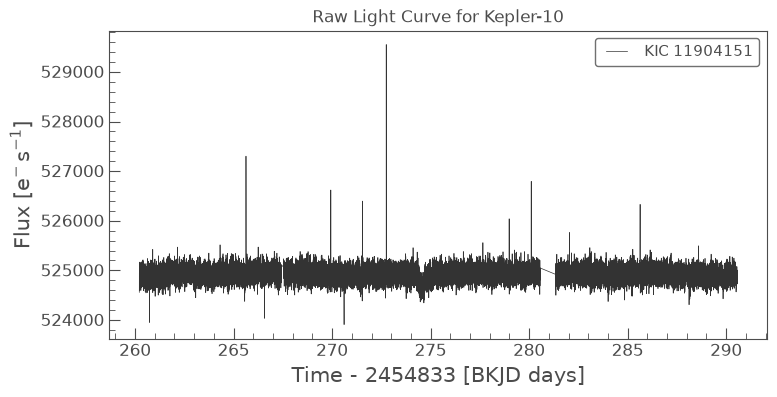

In [10]:
lc.plot()
plt.title("Raw Light Curve for Kepler-10")
plt.show()

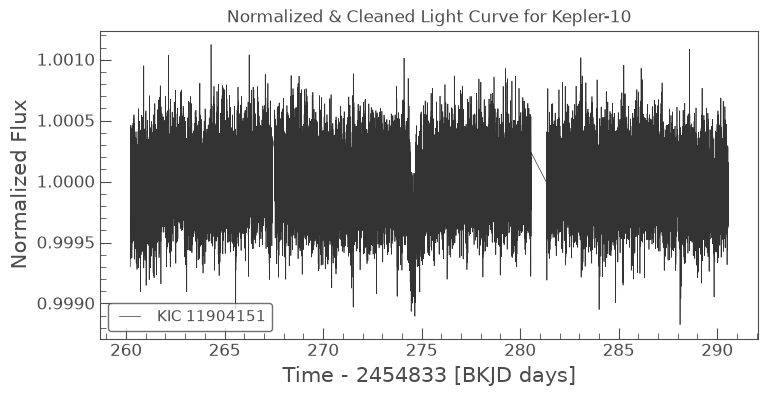

In [11]:
# 1. Clean, remove outliers, and normalize all in one fluid chain
lc_clean = lc.remove_nans().remove_outliers(sigma=5).normalize()

# 2. Plot the newly created clean object
lc_clean.plot()

# 3. Add visual titles and force the graph to render
plt.title("Normalized & Cleaned Light Curve for Kepler-10")
plt.show()

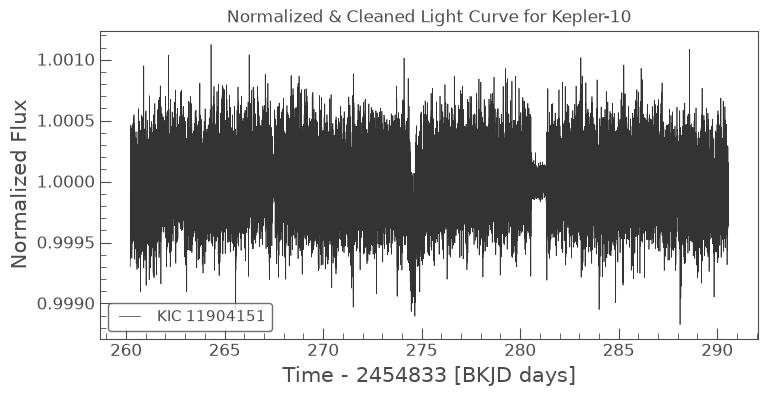

In [12]:
# Add .fill_gaps() to the end of your chain
lc_clean = lc.remove_nans().remove_outliers(sigma=5).normalize().fill_gaps()
lc_clean.plot()

plt.title("Normalized & Cleaned Light Curve for Kepler-10")
plt.show()